In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
%pip install textblob
%pip install ploty.express

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 1.5 MB/s  0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 9.1 MB/s eta 0:00:01
   ------------ --------------------------- 0.5/1.7 MB 9.1 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.7 MB/s  0:00:00

   ---------------------------------------- 0/7 [tqdm]
   ----- ---------------------------------- 1/7 [regex]
   ----- ---------------------------------- 1/7 [regex]
   ----------------- ---------------------- 3/7 [click]
   ----------------- --------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement ploty.express (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for ploty.express


In [4]:
from textblob import TextBlob

In [5]:
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [7]:
apps = pd.read_csv(r"C:\Users\HC\Documents\googleplaystore.csv")

In [8]:
reviews = pd.read_csv(r"C:\Users\HC\Documents\googleplaystore_user_reviews.csv")

In [9]:
display(apps.head())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [10]:
display(reviews.head())

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [11]:
print("Apps Dataset Rows:", apps.shape[0])
print("Apps Dataset Columns:", apps.shape[1])

Apps Dataset Rows: 10841
Apps Dataset Columns: 13


In [12]:
print("Reviews Dataset Rows:", reviews.shape[0])
print("Reviews Dataset Columns:", reviews.shape[1])

Reviews Dataset Rows: 64295
Reviews Dataset Columns: 5


In [13]:
apps.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [14]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 2.5 MB


In [15]:
print(apps.columns.tolist())

['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']


In [16]:
print(reviews.columns.tolist())

['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [17]:
display(reviews.describe(include="all"))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
count,64295,37427,37432,37432.000000,37432.000000
unique,1074,27994,3,NaN,NaN
top,Angry Birds Classic,Good,Positive,NaN,NaN
freq,320,247,23998,NaN,NaN
mean,NaN,NaN,NaN,0.182146,0.492704
std,NaN,NaN,NaN,0.351301,0.259949
min,NaN,NaN,NaN,-1.000000,0.000000
25%,NaN,NaN,NaN,0.000000,0.357143
50%,NaN,NaN,NaN,0.150000,0.514286
75%,NaN,NaN,NaN,0.400000,0.650000


In [18]:
display(apps.isnull().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [19]:
display(reviews.isnull().sum())

App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

In [20]:
print("Duplicate Review Rows:", reviews.duplicated().sum())

Duplicate Review Rows: 33616


In [21]:
apps_quality = pd.DataFrame({
    "Data Type": apps.dtypes.astype(str),
    "Missing Values": apps.isnull().sum(),
    "Missing Percentage": (apps.isnull().mean() * 100).round(2),
    "Unique Values": apps.nunique()})
display(apps_quality)

,Data Type,Missing Values,Missing Percentage,Unique Values
App,str,0,0.00,9660
Category,str,0,0.00,34
Rating,float64,1474,13.60,40
Reviews,str,0,0.00,6002
Size,str,0,0.00,462
Installs,str,0,0.00,22
Type,str,1,0.01,3
Price,str,0,0.00,93
Content Rating,str,1,0.01,6
Genres,str,0,0.00,120


In [22]:
reviews_quality = pd.DataFrame({
    "Data Type": reviews.dtypes.astype(str),
    "Missing Values": reviews.isnull().sum(),
    "Missing Percentage": (reviews.isnull().mean() * 100).round(2),
    "Unique Values": reviews.nunique()})
display(reviews_quality)

,Data Type,Missing Values,Missing Percentage,Unique Values
App,str,0,0.00,1074
Translated_Review,str,26868,41.79,27994
Sentiment,str,26863,41.78,3
Sentiment_Polarity,float64,26863,41.78,5410
Sentiment_Subjectivity,float64,26863,41.78,4474


In [23]:
apps_before_rows = len(apps)
apps_before_nulls = apps.isnull().sum().sum()
apps_before_duplicates = apps.duplicated().sum()
print("Rows:", apps_before_rows)
print("Missing Values:", apps_before_nulls)
print("Duplicate Rows:", apps_before_duplicates)

Rows: 10841
Missing Values: 1487
Duplicate Rows: 483


In [24]:
reviews_before_rows = len(reviews)
reviews_before_nulls = reviews.isnull().sum().sum()
reviews_before_duplicates = reviews.duplicated().sum()
print("Rows:", reviews_before_rows)
print("Missing Values:", reviews_before_nulls)
print("Duplicate Rows:", reviews_before_duplicates)

Rows: 64295
Missing Values: 107457
Duplicate Rows: 33616


In [25]:
apps = apps.drop_duplicates().copy()
print("Apps after duplicate removal:", len(apps))

Apps after duplicate removal: 10358


In [26]:
reviews = reviews.drop_duplicates().copy()
print("Reviews after duplicate removal:", len(reviews))

Reviews after duplicate removal: 30679


In [27]:
apps["App"] = apps["App"].astype(str).str.strip()

In [28]:
apps["Category"] = apps["Category"].astype(str).str.strip().str.upper()

In [29]:
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")

In [30]:
apps.loc[
    (apps["Rating"] < 0) | (apps["Rating"] > 5),
    "Rating"
] = np.nan

In [31]:
apps["Rating"] = apps["Rating"].fillna(
    apps.groupby("Category")["Rating"].transform("median"))
apps["Rating"] = apps["Rating"].fillna(apps["Rating"].median())

In [32]:
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")

In [33]:
apps["Installs"] = (
    apps["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False))
apps["Installs"] = pd.to_numeric(apps["Installs"], errors="coerce")

In [34]:
apps["Installs"] = apps["Installs"].fillna(
    apps["Installs"].median())

In [35]:
apps["Price"] = (
    apps["Price"]
    .astype(str)
    .str.replace("$", "", regex=False))
apps["Price"] = pd.to_numeric(apps["Price"], errors="coerce")

In [36]:
apps["Price"] = apps["Price"].fillna(0)

In [37]:
def convert_size(value):
    value = str(value).strip()
    if value in ["nan", "Varies with device"]:
        return np.nan
    try:
        if value.endswith("M"):
            return float(value[:-1])
        elif value.endswith("k"):
            return float(value[:-1]) / 1024
    except ValueError:
        return np.nan
    return np.nan
apps["Size_MB"] = apps["Size"].apply(convert_size)

In [38]:
apps["Size_MB"] = apps["Size_MB"].fillna(
    apps["Size_MB"].median())

In [39]:
apps["Category"] = apps["Category"].replace("NAN", np.nan)
apps["Category"] = apps["Category"].fillna("UNKNOWN")

In [40]:
apps["Content Rating"] = apps["Content Rating"].fillna("Not Specified")

In [41]:
apps["Type"] = apps["Type"].astype(str).str.strip().str.title()
apps["Type"] = apps["Type"].replace("Nan", "Free")

In [42]:
apps["Last Updated"] = pd.to_datetime(
    apps["Last Updated"],
    errors="coerce")

In [43]:
apps["Current Ver"] = apps["Current Ver"].fillna("Unknown").astype(str)
apps["Android Ver"] = apps["Android Ver"].fillna("Unknown").astype(str)

In [44]:
apps["App_Type"] = np.where(apps["Price"] > 0, "Paid", "Free")
display(apps[["App", "Price", "App_Type"]].head())

,App,Price,App_Type
0,Photo Editor & Candy Camera & Grid & ScrapBook,0.0,Free
1,Coloring book moana,0.0,Free
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",0.0,Free
3,Sketch - Draw & Paint,0.0,Free
4,Pixel Draw - Number Art Coloring Book,0.0,Free


In [45]:
reviews["Translated_Review"] = (
    reviews["Translated_Review"]
    .fillna("")
    .astype(str)
    .str.strip())

In [46]:
reviews = reviews[
    reviews["Translated_Review"].str.len() > 0
].copy()

In [47]:
reviews["App"] = reviews["App"].astype(str).str.strip()

In [48]:
reviews["Sentiment_Polarity"] = pd.to_numeric(
    reviews["Sentiment_Polarity"],
    errors="coerce")

In [49]:
reviews["Sentiment_Subjectivity"] = pd.to_numeric(
    reviews["Sentiment_Subjectivity"],
    errors="coerce")

In [50]:
category_counts = apps["Category"].value_counts()
display(category_counts)

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
1.9                       1
Name: count, dtype: int64

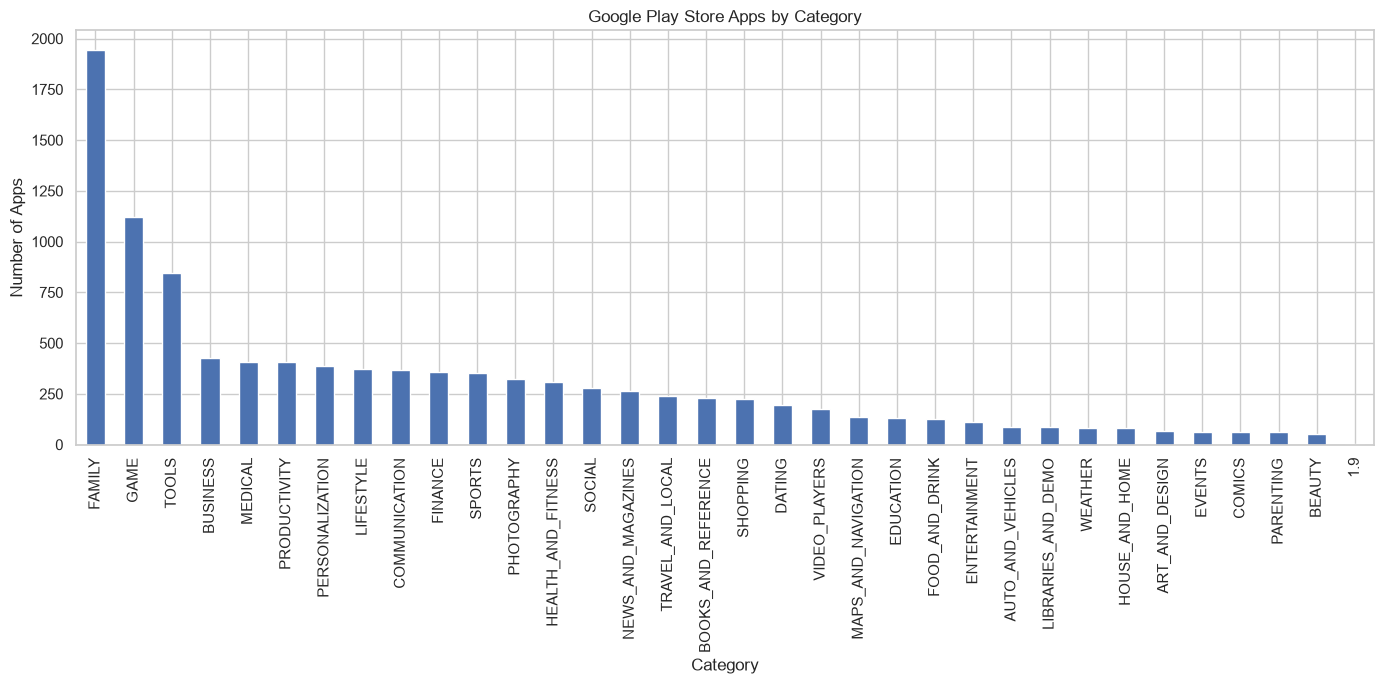

In [51]:
plt.figure(figsize=(14, 7))
category_counts.plot(kind="bar")
plt.title("Google Play Store Apps by Category")
plt.xlabel("Category")
plt.ylabel("Number of Apps")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [52]:
display(category_counts.head(10))

Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64

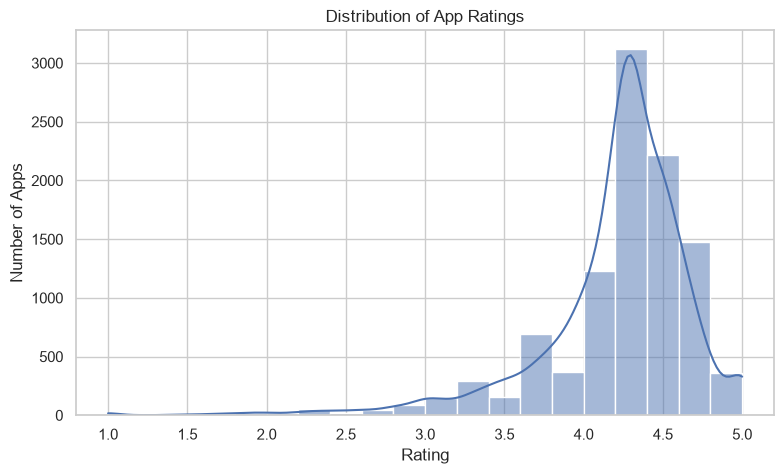

In [53]:
plt.figure(figsize=(9, 5))
sns.histplot(apps["Rating"].dropna(), bins=20, kde=True)
plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.show()

In [54]:
average_ratings = (
    apps.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False))
display(average_ratings)

Category
EVENTS                 4.454688
BOOKS_AND_REFERENCE    4.382609
EDUCATION              4.376154
ART_AND_DESIGN         4.360000
PERSONALIZATION        4.347165
PARENTING              4.316667
1.9                    4.300000
HEALTH_AND_FITNESS     4.295752
BEAUTY                 4.283019
GAME                   4.282070
SOCIAL                 4.260714
SHOPPING               4.256250
WEATHER                4.248780
SPORTS                 4.239031
PRODUCTIVITY           4.219410
MEDICAL                4.212990
AUTO_AND_VEHICLES      4.205882
FAMILY                 4.203757
PHOTOGRAPHY            4.189441
FOOD_AND_DRINK         4.183871
LIBRARIES_AND_DEMO     4.183529
COMMUNICATION          4.175410
HOUSE_AND_HOME         4.170000
COMICS                 4.163333
BUSINESS               4.156792
FINANCE                4.148056
NEWS_AND_MAGAZINES     4.142045
ENTERTAINMENT          4.136036
LIFESTYLE              4.115013
TRAVEL_AND_LOCAL       4.108439
VIDEO_PLAYERS          4.075429

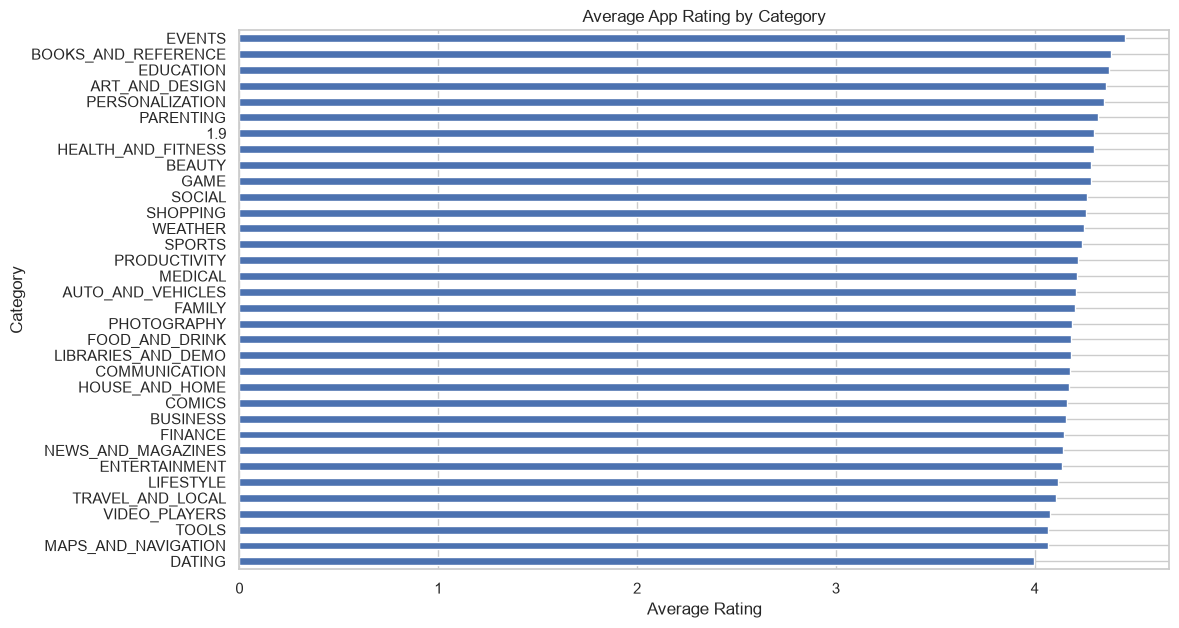

In [55]:
plt.figure(figsize=(12, 7))
average_ratings.sort_values().plot(kind="barh")
plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.show()

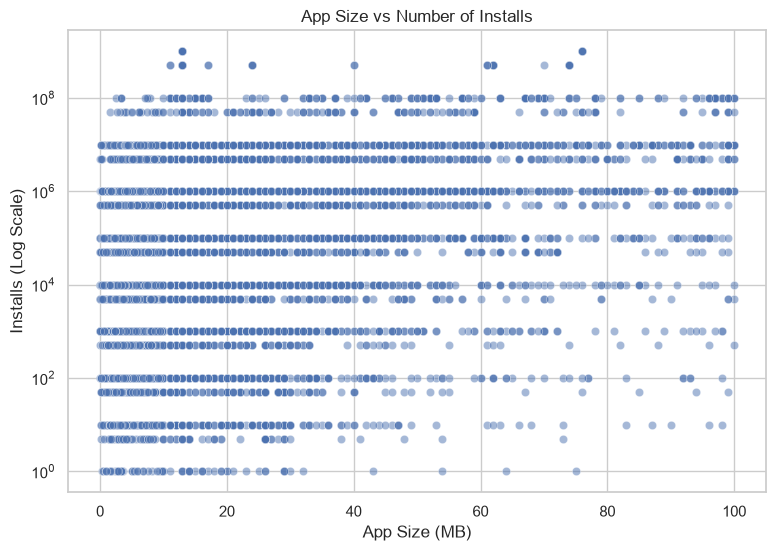

In [56]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=apps,
    x="Size_MB",
    y="Installs",
    alpha=0.5)
plt.yscale("log")
plt.title("App Size vs Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Installs (Log Scale)")
plt.show()

In [57]:
size_correlation = apps[["Size_MB", "Installs"]].corr()
display(size_correlation)

,Size_MB,Installs
Size_MB,1.000000,0.050127
Installs,0.050127,1.000000


In [58]:
type_counts = apps["App_Type"].value_counts()
display(type_counts)

App_Type
Free    9593
Paid     765
Name: count, dtype: int64

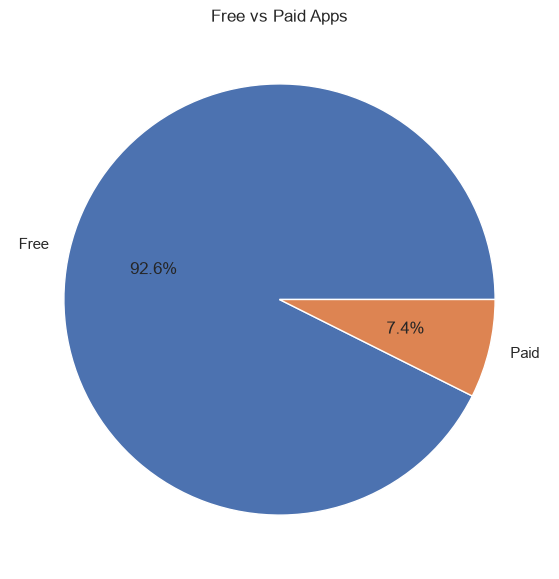

In [60]:
plt.figure(figsize=(7, 7))
plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%")
plt.title("Free vs Paid Apps")
plt.show()

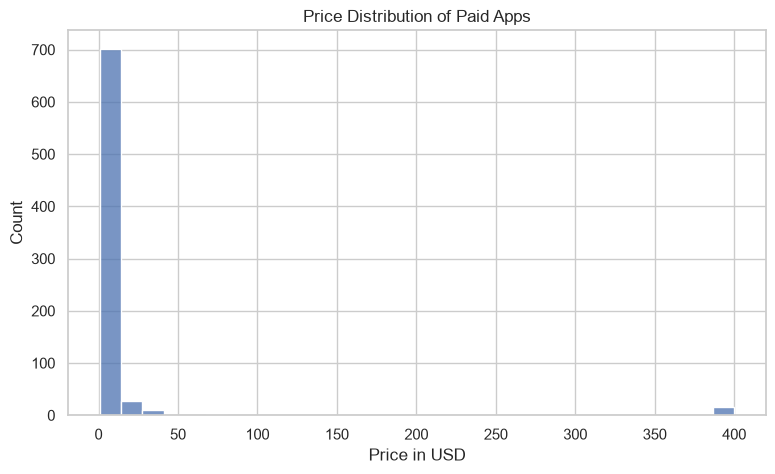

In [61]:
paid_apps = apps[apps["Price"] > 0]
plt.figure(figsize=(9, 5))
sns.histplot(paid_apps["Price"], bins=30)
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price in USD")
plt.show()

In [62]:
apps["Estimated_Revenue"] = apps["Price"] * apps["Installs"]
category_revenue = (
    apps.groupby("Category")["Estimated_Revenue"]
    .sum()
    .sort_values(ascending=False))
display(category_revenue)

Category
FAMILY                 1.857803e+08
LIFESTYLE              5.758394e+07
GAME                   4.098764e+07
FINANCE                2.572668e+07
PHOTOGRAPHY            8.942768e+06
MEDICAL                8.456536e+06
PERSONALIZATION        7.786948e+06
TOOLS                  5.464821e+06
SPORTS                 4.706212e+06
PRODUCTIVITY           4.313375e+06
COMMUNICATION          4.247364e+06
WEATHER                4.181380e+06
EDUCATION              2.403980e+06
HEALTH_AND_FITNESS     1.426069e+06
MAPS_AND_NAVIGATION    1.240789e+06
TRAVEL_AND_LOCAL       1.151504e+06
BUSINESS               1.050543e+06
ENTERTAINMENT          7.980000e+05
VIDEO_PLAYERS          3.352900e+05
FOOD_AND_DRINK         2.844000e+05
PARENTING              2.499590e+05
AUTO_AND_VEHICLES      1.001485e+05
BOOKS_AND_REFERENCE    9.022674e+04
DATING                 8.836150e+04
ART_AND_DESIGN         3.184000e+04
SHOPPING               3.014900e+04
NEWS_AND_MAGAZINES     6.445000e+03
SOCIAL             

In [63]:
def calculate_polarity(text):
    return TextBlob(text).sentiment.polarity
reviews["Polarity"] = reviews["Translated_Review"].apply(
    calculate_polarity)

In [64]:
def calculate_subjectivity(text):
    return TextBlob(text).sentiment.subjectivity
reviews["Subjectivity"] = reviews["Translated_Review"].apply(
    calculate_subjectivity)

In [65]:
def classify_sentiment(value):
    if value > 0:
        return "Positive"
    elif value < 0:
        return "Negative"
    else:
        return "Neutral"
reviews["Sentiment_Label"] = reviews["Polarity"].apply(
    classify_sentiment)

In [66]:
sentiment_counts = reviews["Sentiment_Label"].value_counts()
display(sentiment_counts)

Sentiment_Label
Positive    19014
Negative     6322
Neutral      4356
Name: count, dtype: int64

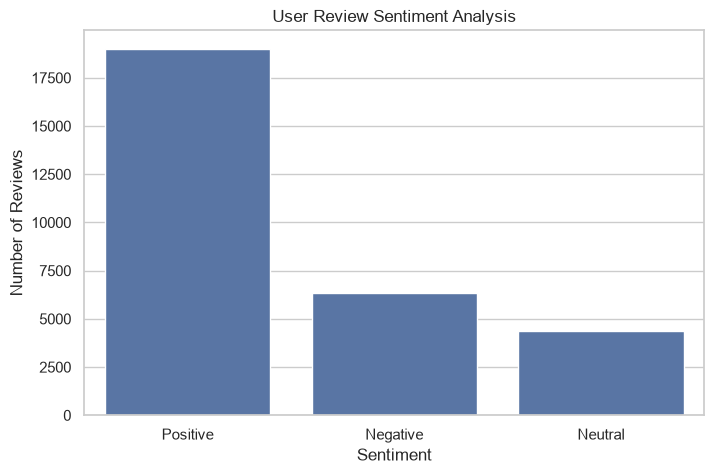

In [67]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=reviews,
    x="Sentiment_Label",
    order=["Positive", "Negative", "Neutral"])
plt.title("User Review Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [68]:
app_categories = apps[["App", "Category"]].drop_duplicates("App")
reviews_with_category = reviews.merge(
    app_categories,
    on="App",
    how="left")
display(reviews_with_category.head())

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,Polarity,Subjectivity,Sentiment_Label,Category
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,1.00,0.533333,Positive,HEALTH_AND_FITNESS
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,0.25,0.288462,Positive,HEALTH_AND_FITNESS
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,0.40,0.875000,Positive,HEALTH_AND_FITNESS
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000,1.00,0.300000,Positive,HEALTH_AND_FITNESS
4,10 Best Foods for You,Best way,Positive,1.00,0.300000,1.00,0.300000,Positive,HEALTH_AND_FITNESS


In [69]:
category_sentiment = (
    reviews_with_category.groupby("Category")["Polarity"]
    .mean()
    .sort_values(ascending=False))
display(category_sentiment)

Category
COMICS                 0.449810
EVENTS                 0.375086
AUTO_AND_VEHICLES      0.343119
PARENTING              0.313316
EDUCATION              0.297454
HEALTH_AND_FITNESS     0.294396
WEATHER                0.281344
FOOD_AND_DRINK         0.279847
PERSONALIZATION        0.274741
MAPS_AND_NAVIGATION    0.259767
BOOKS_AND_REFERENCE    0.258982
LIBRARIES_AND_DEMO     0.239990
ART_AND_DESIGN         0.233363
MEDICAL                0.226539
HOUSE_AND_HOME         0.224876
PHOTOGRAPHY            0.224834
LIFESTYLE              0.224727
TOOLS                  0.213829
TRAVEL_AND_LOCAL       0.212001
SHOPPING               0.202583
BEAUTY                 0.199734
BUSINESS               0.199730
SPORTS                 0.195027
PRODUCTIVITY           0.194531
DATING                 0.179436
FINANCE                0.171977
COMMUNICATION          0.171862
NEWS_AND_MAGAZINES     0.152946
VIDEO_PLAYERS          0.136103
ENTERTAINMENT          0.133953
FAMILY                 0.119083

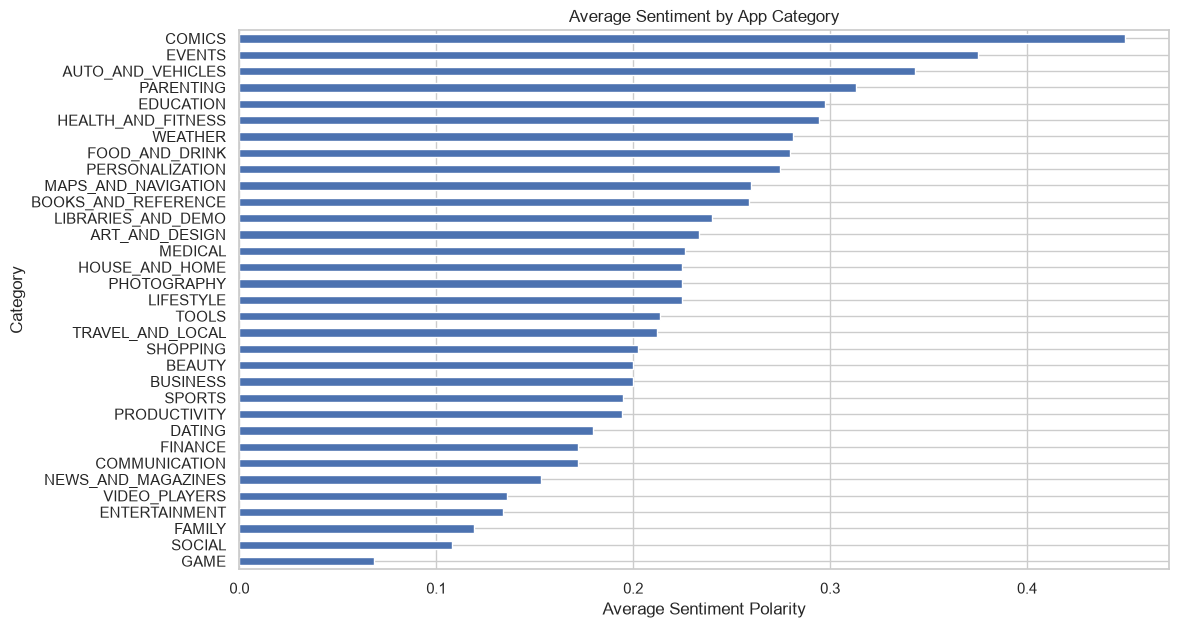

In [70]:
plt.figure(figsize=(12, 7))
category_sentiment.sort_values().plot(kind="barh")
plt.title("Average Sentiment by App Category")
plt.xlabel("Average Sentiment Polarity")
plt.show()

In [75]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 3.2 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.7 MB 5.6 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.7 MB 5.4 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.7 MB 4.9 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.7 MB 4.4 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.7 MB 3.8 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 3.7 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 3.7 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 3.7 MB/s eta 0:00:02
   ---------------------- -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [76]:
import plotly.express as px

In [77]:
category_chart = (
    category_counts
    .rename_axis("Category")
    .reset_index(name="Number_of_Apps"))
fig = px.bar(
    category_chart,
    x="Category",
    y="Number_of_Apps",
    title="Interactive Google Play Store App Categories",
    color="Number_of_Apps")
fig.show()

In [80]:
rating_chart = average_ratings.rename_axis(
    "Category"
).reset_index(name="Average_Rating")
fig = px.bar(
    rating_chart,
    x="Category",
    y="Average_Rating",
    title="Average App Ratings by Category",
    color="Average_Rating")
fig.show()

In [81]:
print("Top 5 Categories with Most Apps:")
display(category_counts.head(5))

Top 5 Categories with Most Apps:


Category
FAMILY      1943
GAME        1121
TOOLS        843
BUSINESS     427
MEDICAL      408
Name: count, dtype: int64

In [82]:
print("Top 5 Categories by Average Rating:")
display(average_ratings.head(5))

Top 5 Categories by Average Rating:


Category
EVENTS                 4.454688
BOOKS_AND_REFERENCE    4.382609
EDUCATION              4.376154
ART_AND_DESIGN         4.360000
PERSONALIZATION        4.347165
Name: Rating, dtype: float64

In [83]:
print("Most Positive Sentiment Category:")
print(category_sentiment.idxmax())
print("\nMost Negative Sentiment Category:")
print(category_sentiment.idxmin())

Most Positive Sentiment Category:
COMICS

Most Negative Sentiment Category:
GAME


In [84]:
print("PROJECT CONCLUSION")
print("1. Category analysis helps identify the most competitive app categories.")
print("2. Rating analysis helps developers understand app quality and user satisfaction.")
print("3. Sentiment analysis helps developers understand positive and negative user feedback.")

PROJECT CONCLUSION
1. Category analysis helps identify the most competitive app categories.
2. Rating analysis helps developers understand app quality and user satisfaction.
3. Sentiment analysis helps developers understand positive and negative user feedback.


In [85]:
apps.to_csv("cleaned_googleplaystore.csv", index=False)
print("Cleaned Apps Dataset Saved Successfully!")

Cleaned Apps Dataset Saved Successfully!


In [86]:
reviews_with_category.to_csv(
    "googleplaystore_sentiment_analysis.csv",
    index=False)
print("Sentiment Analysis Results Saved Successfully!")

Sentiment Analysis Results Saved Successfully!


In [87]:
import os
files = [
    "cleaned_googleplaystore.csv",
    "cleaned_googleplaystore_reviews.csv",
    "googleplaystore_sentiment_analysis.csv"]
for file in files:
    print(file, ":", os.path.exists(file))

cleaned_googleplaystore.csv : True
cleaned_googleplaystore_reviews.csv : False
googleplaystore_sentiment_analysis.csv : True


# Google Play Store Analysis – Project Overview

## Objective
The objective of this project is to analyze Google Play Store applications and user reviews to understand app categories, ratings, installations, pricing and customer sentiment.

## Data Cleaning
Missing values were handled, duplicate records were removed, numerical columns were corrected and app sizes were converted into MB.

## Category Analysis
Apps were grouped by category to identify the categories with the highest number of applications.

## Rating Analysis
App ratings were analyzed to understand average ratings and user satisfaction across different categories.

## Size and Installs Analysis
A scatter plot and correlation analysis were used to examine the relationship between app size and installations.

## Pricing Analysis
Free and paid applications were compared. Paid app prices and estimated revenue by category were also examined.

## Sentiment Analysis
TextBlob was used to classify user reviews as positive, negative or neutral. Average sentiment was also compared across app categories.

## Conclusion
The analysis provides useful insights about app competition, ratings, pricing and user feedback. These findings can help developers make better decisions when planning a new application.